# 2. Dataset Preparation and Indexing

This notebook prepares the ECG dataset for the next stages of the analysis pipeline. It locates the available `.mat` files, extracts metadata encoded in their filenames, and organizes this information into a structured index. The resulting table links each recording to its patient, precordial lead, class label, original path, and cleaned filename.

The workflow then validates the metadata, compares the recordings with the annotation CSV, and inspects the internal structure and numerical quality of every signal. Signal lengths and representative waveforms are also analyzed to identify differences that may affect later preprocessing. Files are not renamed, moved, or modified, and training, validation, and test sets are not created in this notebook.

## 2.1 Library Imports and Path Definition

The required libraries are imported and the directory containing the ECG recordings is defined. Before reading any files, the code verifies that `data/all_signals` exists and reports the path that will be explored.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat

# Path to the signal directory
signals_path = Path("data") / "all_signals"

# Check that the directory exists
if not signals_path.is_dir():
    raise FileNotFoundError(
        f"No existe la carpeta de señales: {signals_path}"
    )

print(f"Signal directory: {signals_path}")
print("The directory exists and is ready to be explored.")

Signal directory: data/all_signals
The directory exists and is ready to be explored.


## 2.2 Locating `.mat` Files

All `.mat` files located directly inside `all_signals` are collected in sorted order. The total number of files is reported, and the first and last five filenames are displayed to verify that the search is correct and that the original filenames are preserved.

In [2]:
mat_files = sorted(
    signals_path.glob("*.mat")
)

if len(mat_files) == 0:
    raise FileNotFoundError(
        "No se encontraron archivos .mat."
    )

print(
    f"Total number of .mat files: "
    f"{len(mat_files):,}"
)

print("\nFirst five files:")
for file_path in mat_files[:5]:
    print(file_path.name)

print("\nLast five files:")
for file_path in mat_files[-5:]:
    print(file_path.name)

Total number of .mat files: 10,592

First five files:
Para_alumna_Brugada\all_signals\BH0002_1_101372_1_V1_99.mat
Para_alumna_Brugada\all_signals\BH0002_1_101372_1_V2_99.mat
Para_alumna_Brugada\all_signals\BH0002_1_101372_1_V3_99.mat
Para_alumna_Brugada\all_signals\BH0002_1_101372_1_V4_99.mat
Para_alumna_Brugada\all_signals\BH0002_1_101372_V5_1.mat

Last five files:
Para_alumna_Brugada\all_signals\BH0103_5_1113285_V4_99.mat
Para_alumna_Brugada\all_signals\BH0103_5_1113285_V5_99.mat
Para_alumna_Brugada\all_signals\BH0103_5_1113285_V6_99.mat
Para_alumna_Brugada\all_signals\BH0103_5_1114371_V2_99.mat
Para_alumna_Brugada\all_signals\BH0103_5_1114371_V5_99.mat


## 2.3 Extracting Metadata from Filenames

A cleaned version of each filename is created in memory without changing the original file. The first filename component identifies the patient, the penultimate component identifies the precordial lead, and the final component identifies the class label. Intermediate components are intentionally not interpreted because the dataset contains two filename formats.

In [3]:
metadata_records = []

for file_path in mat_files:
    # Work with the part that starts with BH.
    clean_filename = file_path.stem.split("\\")[-1]
    name_parts = clean_filename.split("_")

    # The first part of the filename is always the patient identifier.
    patient_id = name_parts[0]

    # The penultimate part is always the precordial lead.
    lead = name_parts[-2]

    # The last part is always the class label.
    label = int(name_parts[-1])

    metadata_records.append(
        {
            "patient_id": patient_id,
            "lead": lead,
            "label": label,
            "mat_path": file_path.resolve(),
            "original_filename": file_path.name,
            "clean_filename": clean_filename,
        }
    )

print(
    f"Extracted metadata records: "
    f"{len(metadata_records):,}"
)

print("Metadata example:")
print(metadata_records[0])

Extracted metadata records: 10,592
Metadata example:
{'patient_id': 'BH0002', 'lead': 'V1', 'label': 99, 'mat_path': PosixPath('/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimiento-de-patrones-en-se-ales-ECG-con-ML/notebooks/data/all_signals/Para_alumna_Brugada\\all_signals\\BH0002_1_101372_1_V1_99.mat'), 'original_filename': 'Para_alumna_Brugada\\all_signals\\BH0002_1_101372_1_V1_99.mat', 'clean_filename': 'BH0002_1_101372_1_V1_99'}


## 2.4 Creating the Dataset Index

The metadata records are converted into `dataset_index`, with one row per `.mat` file. The section reports its dimensions and the main distributions by class, lead, and patient. It also validates that patient identifiers begin with `BH`, leads belong to `V1`–`V6`, and labels are restricted to the expected values `{1, 99}`.

In [4]:
# Create the index with one row per signal and original file.
dataset_index = pd.DataFrame(metadata_records)

print("First rows of dataset_index:")
display(dataset_index.head())

print(
    f"Shape of dataset_index: "
    f"{dataset_index.shape}"
)

print(
    f"Number of unique patients: "
    f"{dataset_index['patient_id'].nunique():,}"
)

print("Label distribution:")
display(
    dataset_index["label"]
    .value_counts()
    .sort_index()
)

print("Lead distribution:")
display(
    dataset_index["lead"]
    .value_counts()
    .sort_index()
)

print("Number of signals per patient (in .mat files):")
display(
    dataset_index["patient_id"]
    .value_counts()
    
)

# Check the expected format of the extracted metadata.
patient_ids_are_valid = (
    dataset_index["patient_id"]
    .str.startswith("BH")
    .all()
)

leads_are_valid = (
    dataset_index["lead"]
    .isin(["V1", "V2", "V3", "V4", "V5", "V6"])
    .all()
)

labels_are_valid = (
    dataset_index["label"]
    .isin([1, 99])
    .all()
)

print(
    f"All patient_id values start with BH: "
    f"{patient_ids_are_valid}"
)

print(
    f"All lead values belong to V1-V6: "
    f"{leads_are_valid}"
)

print(
    f"All label values belong to {{1, 99}}: "
    f"{labels_are_valid}"
)

First rows of dataset_index:


,patient_id,lead,label,mat_path,original_filename,clean_filename
0,BH0002,V1,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V1_99
1,BH0002,V2,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V2_99
2,BH0002,V3,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V3_99
3,BH0002,V4,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V4_99
4,BH0002,V5,1,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_V5_1


Shape of dataset_index: (10592, 6)
Number of unique patients: 33
Label distribution:


label
1     2011
99    8581
Name: count, dtype: int64

Lead distribution:


lead
V1    1762
V2    1773
V3    1765
V4    1758
V5    1772
V6    1762
Name: count, dtype: int64

Number of signals per patient (in .mat files):


patient_id
BH0002    1638
BH0035     686
BH0003     612
BH0026     528
BH0019     504
BH0030     504
BH0028     468
BH0027     456
BH0032     384
BH0031     384
BH0004     378
BH0025     378
BH0101     368
BH0015     318
BH0022     300
BH0020     300
BH0014     252
BH0006     252
BH0005     246
BH0010     210
BH0007     180
BH0033     180
BH0018     126
BH0023     126
BH0012     126
BH0008     126
BH0009     120
BH0044     117
BH0029      78
BH0036      78
BH0016      72
BH0103      67
BH0017      30
Name: count, dtype: int64

All patient_id values start with BH: True
All lead values belong to V1-V6: True
All label values belong to {1, 99}: True


### 2.4.1 Comparing `.mat` Files with the CSV

The number of `.mat` files is compared with the number of signals recorded in the CSV for each patient. Only patients whose counts differ between the two sources are displayed, making potential inconsistencies easy to identify.

In [5]:
# Load the annotation CSV.
annotations_path = Path("data") / "all_anotaciones.csv"

# Read the CSV and store it in a pandas DataFrame.
annotations_df = pd.read_csv(
    annotations_path,
    sep=None, # pandas automatically detects the separator
    engine="python",
)


# Extract the patient identifier from the "Nombre" column.
csv_patient_counts = (
    annotations_df["Nombre"]
    .str.split("_")
    .str[0]
    .value_counts()
    .rename("csv_signals")
)

# Count the .mat files associated with each patient.
mat_patient_counts = (
    dataset_index["patient_id"]
    .value_counts()
    .rename("mat_signals")
)

# Join both counts using the patient identifier.
patient_counts_comparison = pd.concat(
    [
        mat_patient_counts,
        csv_patient_counts,
    ],
    axis=1,
).fillna(0)

# Convert the counts to integers.
patient_counts_comparison = (
    patient_counts_comparison
    .astype(int)
    .reset_index()
    .rename(columns={"index": "patient_id"})
)

# Keep only patients with different counts.
different_counts = patient_counts_comparison[
    patient_counts_comparison["mat_signals"]
    != patient_counts_comparison["csv_signals"]
]

print(
    "Patients with different numbers of signals "
    "between the .mat files and the CSV:"
)

display(
    different_counts[
        [
            "patient_id",
            "mat_signals",
            "csv_signals",
        ]
    ]
)

Patients with different numbers of signals between the .mat files and the CSV:


,patient_id,mat_signals,csv_signals
0,BH0002,1638,2759
3,BH0026,528,476
4,BH0019,504,280
5,BH0030,504,238
7,BH0027,456,452
10,BH0004,378,126
11,BH0025,378,365
14,BH0022,300,214
19,BH0010,210,196
20,BH0007,180,87


### 2.4.2 Class Distribution by Patient

For each patient, the number of signals in the positive class (`label = 1`) and negative class (`label = 99`) is counted. The total number of signals per patient is also calculated, providing a patient-level view of class composition.

In [6]:
# Count the positive and negative signals for each patient.
signals_by_patient_and_class = pd.crosstab(
    dataset_index["patient_id"],
    dataset_index["label"],
)

# Rename the columns using a clearer description.
signals_by_patient_and_class = (
    signals_by_patient_and_class
    .rename(
        columns={
            1: "positive_signals",
            99: "negative_signals",
        }
    )
    .reindex(
        columns=[
            "positive_signals",
            "negative_signals",
        ],
        fill_value=0,
    )
)

# Calculate the total number of signals per patient.
signals_by_patient_and_class["total_signals"] = (
    signals_by_patient_and_class["positive_signals"]
    + signals_by_patient_and_class["negative_signals"]
)

print(
    "Distribution of positive and negative signals by patient:"
)

display(
    signals_by_patient_and_class
    .sort_index()
)

# Count how many patients have at least one positive signal
# and how many have at least one negative signal.
patients_with_positive_signals = (
    signals_by_patient_and_class["positive_signals"] > 0
).sum()

patients_with_negative_signals = (
    signals_by_patient_and_class["negative_signals"] > 0
).sum()

print(
    "Patients with at least one positive signal:",
    patients_with_positive_signals,
)

print(
    "Patients with at least one negative signal:",
    patients_with_negative_signals,
)

Distribution of positive and negative signals by patient:


label,positive_signals,negative_signals,total_signals
patient_id,,,
BH0002,364,1274,1638
BH0003,0,612,612
BH0004,126,252,378
BH0005,246,0,246
BH0006,0,252,252
BH0007,57,123,180
BH0008,0,126,126
BH0009,39,81,120
BH0010,196,14,210


Patients with at least one positive signal: 15
Patients with at least one negative signal: 32


In [7]:
# Total number of signals per patient.
# Sort patients by total number of signals.
patient_summary = (
    signals_by_patient_and_class
    .copy()
    .sort_values("total_signals")
)

# Calculate the percentages correctly.
patient_percentages = (
    patient_summary[
        [
            "positive_signals",
            "negative_signals",
        ]
    ]
    .div(
        patient_summary["total_signals"],
        axis=0,
    )
    * 100
)

fig_height = max(
    6,
    0.30 * len(patient_summary),
)

fig, ax = plt.subplots(
    figsize=(14, fig_height)
)

# Negative portion of each bar.
negative_bars = ax.barh(
    patient_summary.index.astype(str),
    patient_summary["negative_signals"],
    color="blue",
    label="Sin síndrome",
)

# Positive portion of each bar.
positive_bars = ax.barh(
    patient_summary.index.astype(str),
    patient_summary["positive_signals"],
    left=patient_summary["negative_signals"],
    color="red",
    label="Síndrome positivo",
)

# Display the percentages inside the bars.
for i, patient in enumerate(patient_summary.index):
    negative_percentage = patient_percentages.loc[
        patient,
        "negative_signals",
    ]

    positive_percentage = patient_percentages.loc[
        patient,
        "positive_signals",
    ]

    negative_signals = patient_summary.loc[
        patient,
        "negative_signals",
    ]

    positive_signals = patient_summary.loc[
        patient,
        "positive_signals",
    ]

    # Percentage of negative signals.
    if negative_signals > 0:
        ax.text(
            negative_signals / 2,
            i,
            f"{negative_percentage:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontweight="bold",
        )

    # Percentage of positive signals.
    if positive_signals > 0:
        ax.text(
            negative_signals + positive_signals / 2,
            i,
            f"{positive_percentage:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontweight="bold",
        )

ax.set_title(
    "Número de señales y porcentaje por clase para cada paciente"
)

ax.set_xlabel("Número de señales")
ax.set_ylabel("Paciente")

ax.legend(
    loc="lower right"
)

ax.grid(
    axis="x",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

<Figure size 1400x990 with 1 Axes>

## 2.5 Checking the Internal Structure of All Signals

Each file is loaded and only its signal variable is inspected. The analysis records the key used to access the signal, its length, data type, number of dimensions, and whether it contains `NaN` or `Inf` values. Complete signal arrays are not stored in the index, which avoids unnecessary memory usage.

In [8]:
signal_records = []
total_files = len(mat_files)

for file_number, file_path in enumerate(
    mat_files,
    start=1,
):
    # Load the MATLAB contents without modifying the original file.
    mat_data = loadmat(
        file_path,
        squeeze_me=True,
    )

    # Use the current name while maintaining compatibility with older files.
    if "ecg_signal" in mat_data:
        signal_key = "ecg_signal"
    elif "ecg_guardar" in mat_data:
        signal_key = "ecg_guardar"
    else:
        raise KeyError(
            f"No se encontró la señal en {file_path.name}"
        )

    # Convert the signal to NumPy to inspect its properties.
    ecg_signal = np.asarray(
        mat_data[signal_key]
    )

    signal_records.append(
        {
            "signal_key": signal_key,
            "signal_length": ecg_signal.size,
            "signal_dtype": str(ecg_signal.dtype),
            "signal_ndim": ecg_signal.ndim,
            "contains_nan": np.isnan(ecg_signal).any(),
            "contains_inf": np.isinf(ecg_signal).any(),
        }
    )

    if file_number % 1000 == 0:
        print(
            f"Processed {file_number} "
            f"of {total_files} files"
        )

signal_metadata_df = pd.DataFrame(
    signal_records
)

# Add the properties to dataset_index while preserving
# the order of mat_files.
for column in signal_metadata_df.columns:
    dataset_index[column] = (
        signal_metadata_df[column]
        .to_numpy()
    )

print(
    f"Added "
    f"{len(signal_metadata_df.columns)} "
    f"columnas de calidad."
)

display(dataset_index.head())

Processed 1000 of 10592 files
Processed 2000 of 10592 files
Processed 3000 of 10592 files
Processed 4000 of 10592 files
Processed 5000 of 10592 files
Processed 6000 of 10592 files
Processed 7000 of 10592 files
Processed 8000 of 10592 files
Processed 9000 of 10592 files
Processed 10000 of 10592 files
Added 6 columnas de calidad.


,patient_id,lead,label,mat_path,original_filename,clean_filename,signal_key,signal_length,signal_dtype,signal_ndim,contains_nan,contains_inf
0,BH0002,V1,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V1_99,ecg_signal,801,float64,1,False,False
1,BH0002,V2,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V2_99,ecg_signal,801,float64,1,False,False
2,BH0002,V3,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V3_99,ecg_signal,801,float64,1,False,False
3,BH0002,V4,99,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V4_99,ecg_signal,801,float64,1,False,False
4,BH0002,V5,1,/Users/ainhoa.ns/Desktop/TurraFM/-Reconocimien...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_V5_1,ecg_guardar,252,float64,1,False,False


## 2.6 Analyzing Signal Lengths

The signal keys and quality properties are summarized, including dimensionality and invalid numeric values. The distribution of signal lengths is also analyzed to inform a later decision about resampling to 252 samples. This notebook does not resample, normalize, filter, or remove any file.

In [9]:
# Count how many files use each variable name.
print(
    "Files using ecg_signal:",
    (
        dataset_index["signal_key"]
        == "ecg_signal"
    ).sum(),
)

print(
    "Files using ecg_guardar:",
    (
        dataset_index["signal_key"]
        == "ecg_guardar"
    ).sum(),
)

# Check the shape and numerical quality of the signals.
print(
    "Signals that are not 1D:",
    (
        dataset_index["signal_ndim"]
        != 1
    ).sum(),
)

print(
    "Signals containing NaN:",
    dataset_index["contains_nan"].sum(),
)

print(
    "Signals containing Inf:",
    dataset_index["contains_inf"].sum(),
)

# Calculate summary statistics for signal lengths.
lengths = dataset_index["signal_length"]

print(
    f"Minimum length: "
    f"{lengths.min():,}"
)

print(
    f"Maximum length: "
    f"{lengths.max():,}"
)

print(
    f"Median length: "
    f"{lengths.median():g}"
)

print(
    f"Number of distinct lengths: "
    f"{lengths.nunique():,}"
)

# If there are few lengths, display all of them;
# otherwise, display the 20 most frequent lengths.
length_counts = (
    lengths
    .value_counts()
    .sort_index()
)

if len(length_counts) <= 20:
    print("Complete length table:")

    display(
        length_counts.to_frame(
            name="frequency"
        )
    )
else:
    print("The 20 most frequent lengths:")

    display(
        lengths
        .value_counts()
        .head(20)
        .rename("frequency")
        .to_frame()
    )

Files using ecg_signal: 3615
Files using ecg_guardar: 6977
Signals that are not 1D: 0
Signals containing NaN: 0
Signals containing Inf: 0
Minimum length: 252
Maximum length: 801
Median length: 252
Number of distinct lengths: 2
Complete length table:


,frequency
signal_length,
252,6977
801,3615


## 2.7 Visual Inspection of the Signals

Selected signals from `dataset_index` are plotted to visually inspect the leads, between-patient variability, class differences, and the different signal lengths represented in the dataset.

In [10]:
import matplotlib.pyplot as plt

# Text to display in titles according to the class label.
label_names = {
    1: "Síndrome de Brugada tipo I",
    99: "Sin síndrome",
}


def load_signal(row):
    """Carga la señal indicada en una fila de dataset_index."""
    mat_data = loadmat(
        row["mat_path"],
        squeeze_me=True,
    )

    ecg_signal = np.asarray(
        mat_data[row["signal_key"]]
    )

    return ecg_signal


def make_signal_title(row):
    """Crea un título con la información principal de una señal."""
    syndrome_name = label_names[row["label"]]

    return (
        f"Paciente: {row['patient_id']} | "
        f"Derivación: {row['lead']} | "
        f"{syndrome_name} | "
        f"Muestras: {row['signal_length']}"
    )

### 2.7.1 Six Leads from the Same Patient
A patient with signals in all six precordial leads, V1–V6, is selected reproducibly. One signal from each lead is plotted so that waveform morphology can be compared within the same patient.

Selected patient: BH0004


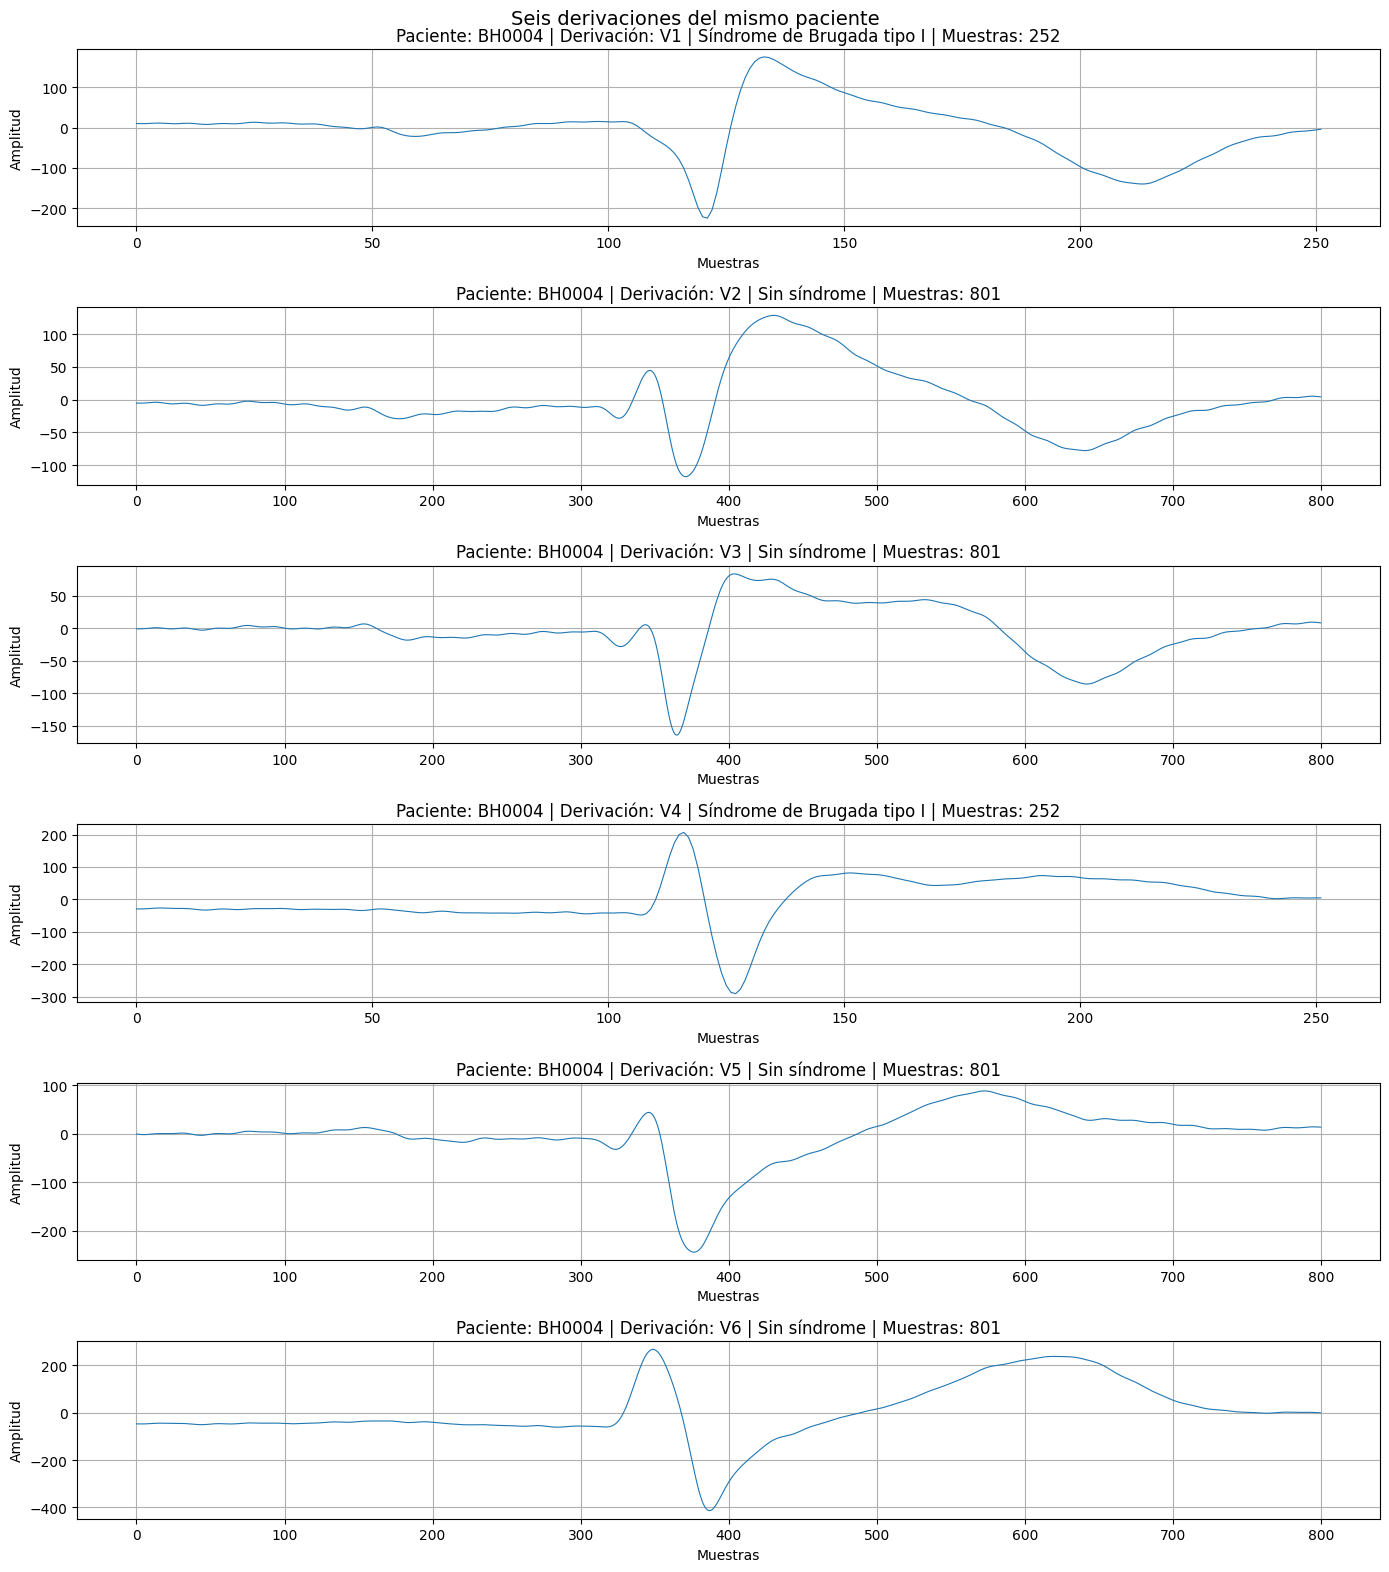

In [11]:
# Identify patients with all six leads.
leads_per_patient = (
    dataset_index
    .groupby("patient_id")["lead"]
    .nunique()
)

patients_with_six_leads = (
    leads_per_patient[
        leads_per_patient == 6
    ]
    .index
    .tolist()
)

if len(patients_with_six_leads) == 0:
    raise ValueError(
        "No hay ningún paciente con las seis derivaciones V1-V6."
    )

# Select a patient reproducibly.
random_generator = np.random.default_rng(42)

selected_patient = random_generator.choice(
    patients_with_six_leads
)

# Select one signal per lead for that patient.
patient_signals = (
    dataset_index[
        dataset_index["patient_id"]
        == selected_patient
    ]
    .drop_duplicates("lead")
    .set_index("lead")
    .loc[["V1", "V2", "V3", "V4", "V5", "V6"]]
    .reset_index()
)

print(
    f"Selected patient: "
    f"{selected_patient}"
)

fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(14, 16),
)

for axis, (_, row) in zip(
    axes,
    patient_signals.iterrows(),
):
    ecg_signal = load_signal(row)
    sample_numbers = np.arange(len(ecg_signal))

    axis.plot(
        sample_numbers,
        ecg_signal,
        linewidth=0.8,
    )

    axis.set_title(
        make_signal_title(row)
    )
    axis.set_xlabel("Muestras")
    axis.set_ylabel("Amplitud")
    axis.grid(True)

fig.suptitle(
    "Seis derivaciones del mismo paciente",
    fontsize=14,
)

fig.tight_layout()
plt.show()

In [12]:
# Identify each beat independently of the lead.
# Start from the cleaned filename and remove the lead
# and the final label.
dataset_index["beat_id"] = (
    dataset_index["clean_filename"]
    .str.replace(
        r"_V[1-6]_(1|99)$",
        "",
        regex=True,
    )
)

# Count how many distinct leads each beat has.
leads_per_beat = (
    dataset_index
    .groupby("beat_id")["lead"]
    .nunique()
)

# Keep only beats that have all six
# precordial leads V1-V6.
beats_with_six_leads = (
    leads_per_beat[
        leads_per_beat == 6
    ]
    .index
    .tolist()
)

if len(beats_with_six_leads) == 0:
    raise ValueError(
        "No hay ningún latido con las seis derivaciones V1-V6."
    )

# Select a beat reproducibly.
random_generator = np.random.default_rng(42)

selected_beat = random_generator.choice(
    beats_with_six_leads
)

# Select the six signals corresponding
# exactly to the same beat.
patient_signals = (
    dataset_index[
        dataset_index["beat_id"]
        == selected_beat
    ]
    .set_index("lead")
    .loc[["V1", "V2", "V3", "V4", "V5", "V6"]]
    .reset_index()
)

selected_patient = (
    patient_signals["patient_id"]
    .iloc[0]
)

print(
    f"Selected patient: "
    f"{selected_patient}"
)

print(
    f"Selected beat: "
    f"{selected_beat}"
)

Selected patient: BH0003
Selected beat: BH0003_3_348706


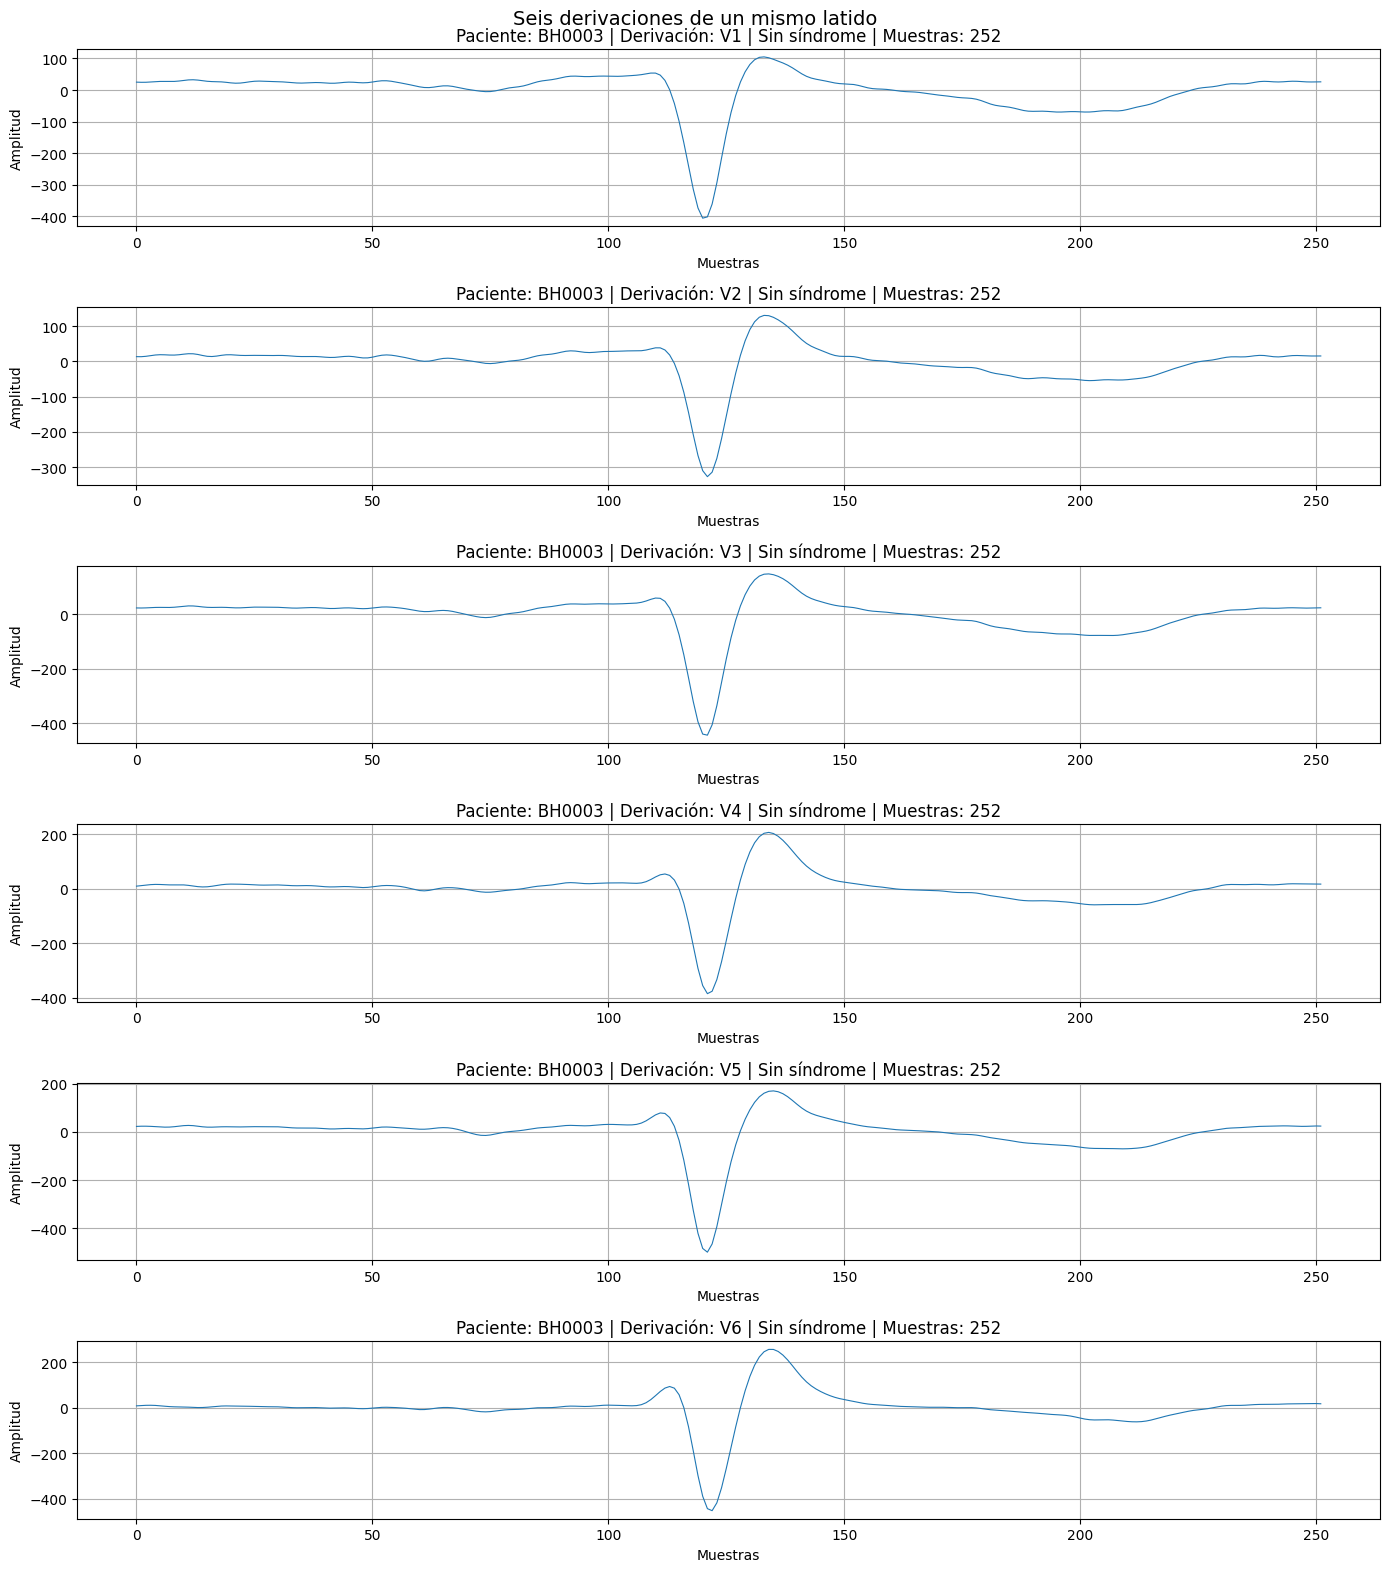

In [13]:
fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(14, 16),
)

for axis, (_, row) in zip(
    axes,
    patient_signals.iterrows(),
):
    ecg_signal = load_signal(row)
    sample_numbers = np.arange(len(ecg_signal))

    axis.plot(
        sample_numbers,
        ecg_signal,
        linewidth=0.8,
    )

    axis.set_title(
        make_signal_title(row)
    )
    axis.set_xlabel("Muestras")
    axis.set_ylabel("Amplitud")
    axis.grid(True)

fig.suptitle(
    "Seis derivaciones de un mismo latido",
    fontsize=14,
)

fig.tight_layout()
plt.show()

### 2.7.2 Patients With and Without the Syndrome

Signals from leads V1 and V2 are shown for patients with type I Brugada syndrome and for patients without the syndrome. Each title identifies the patient, lead, class, and number of samples, making the comparison traceable.

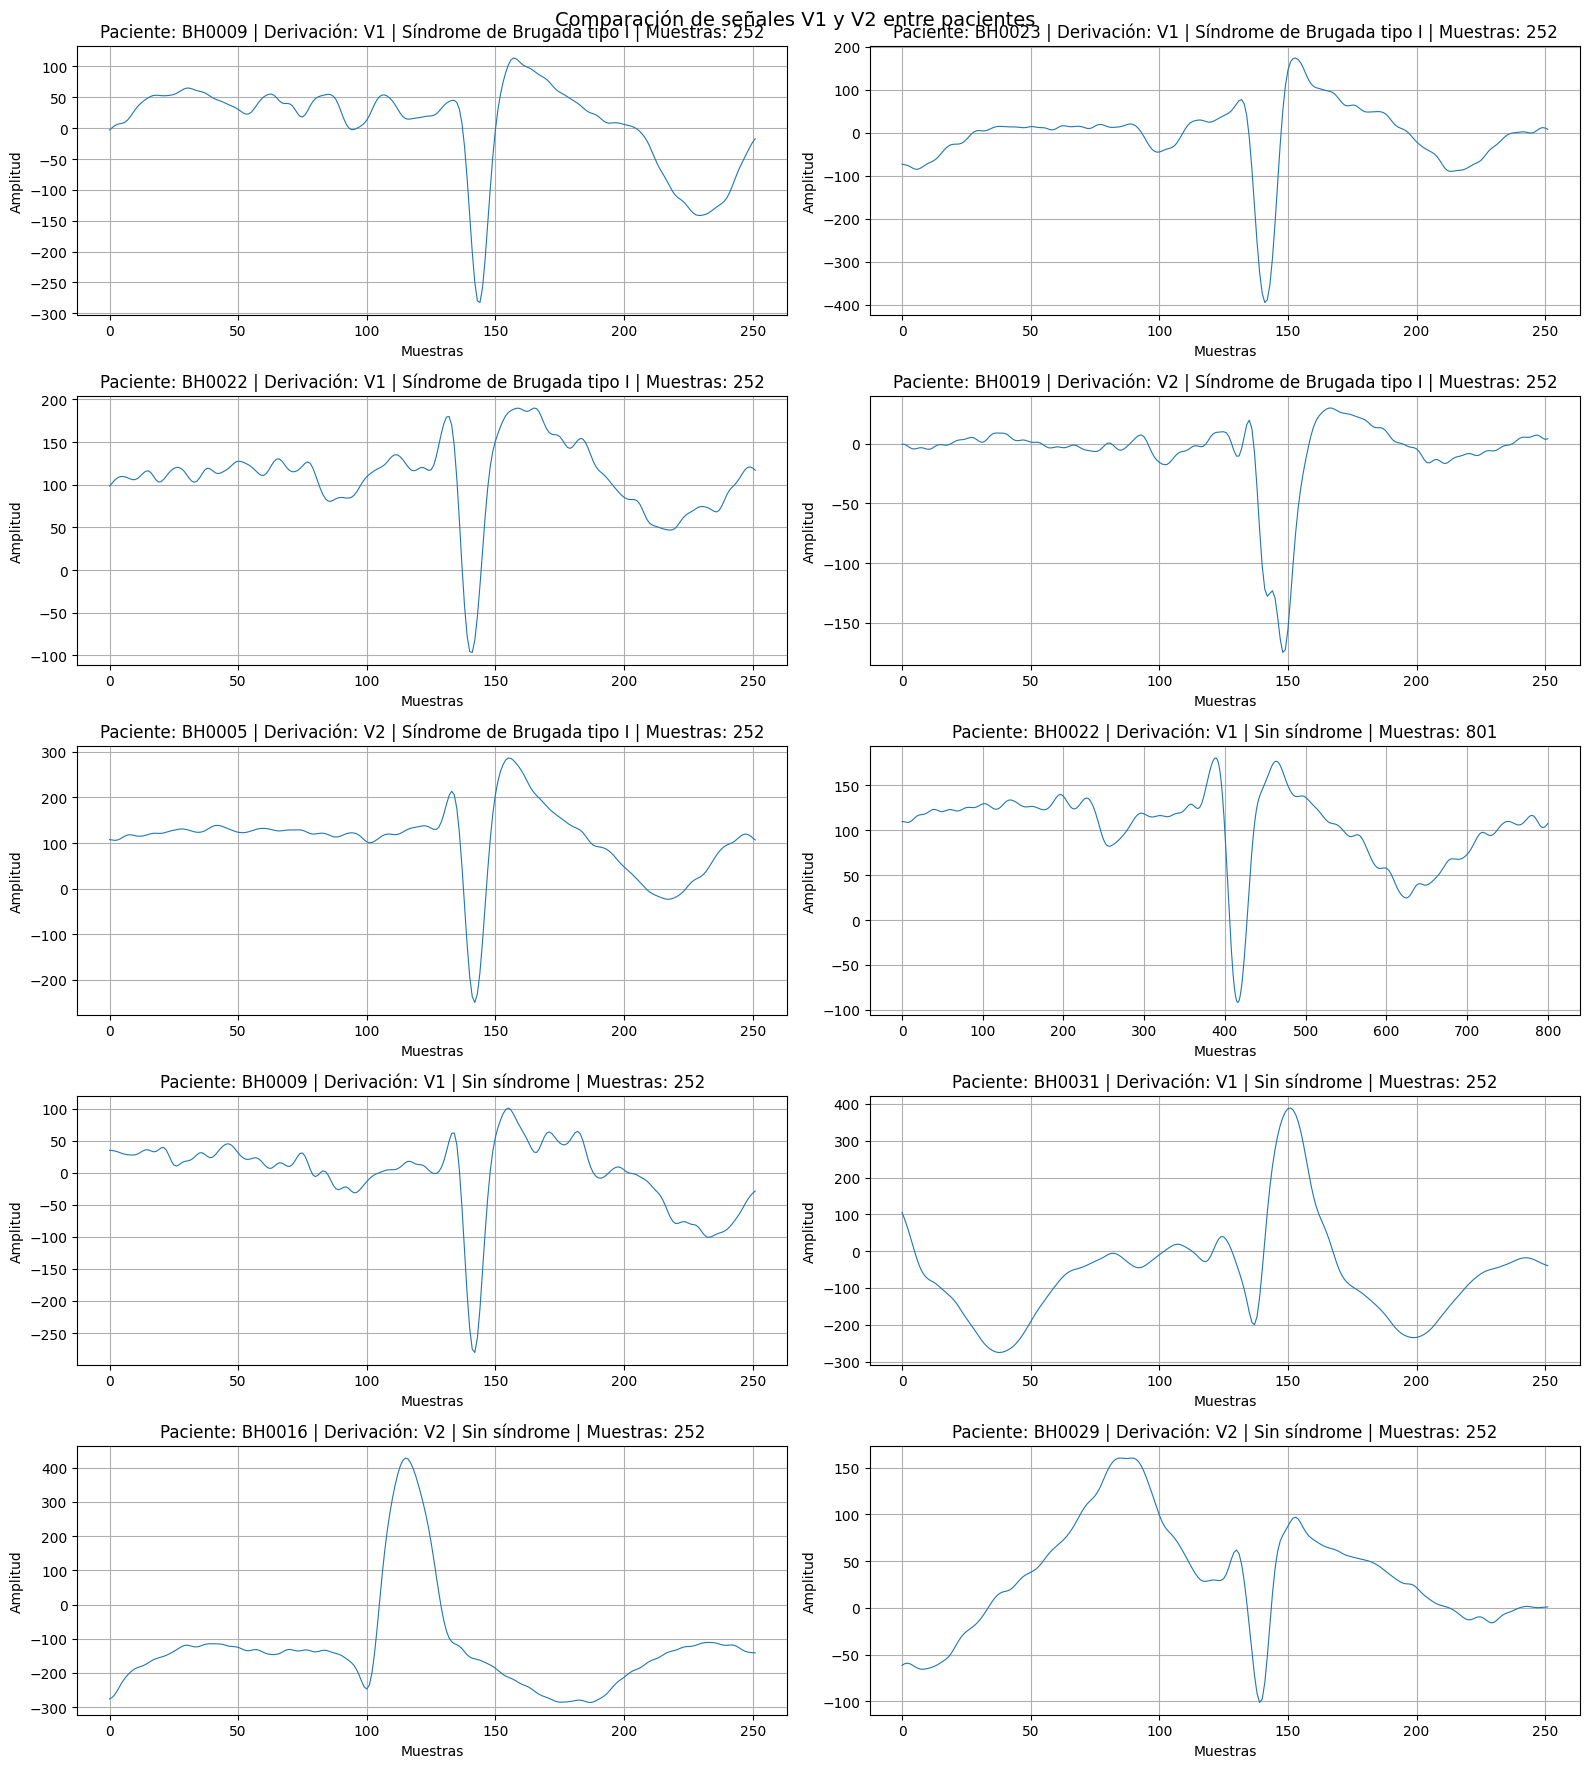

In [14]:
# Select signals from patients with the syndrome in V1.
positive_v1 = (
    dataset_index[
        (dataset_index["label"] == 1)
        & (dataset_index["lead"] == "V1")
    ]
    .drop_duplicates("patient_id")
    .sample(
        n=3,
        random_state=1,
    )
)

# Select signals from patients with the syndrome in V2.
positive_v2 = (
    dataset_index[
        (dataset_index["label"] == 1)
        & (dataset_index["lead"] == "V2")
    ]
    .drop_duplicates("patient_id")
    .sample(
        n=2,
        random_state=2,
    )
)

# Select signals from patients without the syndrome in V1.
negative_v1 = (
    dataset_index[
        (dataset_index["label"] == 99)
        & (dataset_index["lead"] == "V1")
    ]
    .drop_duplicates("patient_id")
    .sample(
        n=3,
        random_state=3,
    )
)

# Select signals from patients without the syndrome in V2.
negative_v2 = (
    dataset_index[
        (dataset_index["label"] == 99)
        & (dataset_index["lead"] == "V2")
    ]
    .drop_duplicates("patient_id")
    .sample(
        n=2,
        random_state=4,
    )
)

selected_signals = pd.concat(
    [
        positive_v1,
        positive_v2,
        negative_v1,
        negative_v2,
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(16, 18),
)

for axis, (_, row) in zip(
    axes.ravel(),
    selected_signals.iterrows(),
):
    ecg_signal = load_signal(row)
    sample_numbers = np.arange(len(ecg_signal))

    axis.plot(
        sample_numbers,
        ecg_signal,
        linewidth=0.8,
    )

    axis.set_title(
        make_signal_title(row)
    )
    axis.set_xlabel("Muestras")
    axis.set_ylabel("Amplitud")
    axis.grid(True)

fig.suptitle(
    "Comparación de señales V1 y V2 entre pacientes",
    fontsize=14,
)

fig.tight_layout()
plt.show()

### 2.7.3 Signals with Different Lengths

Three signals with length 252 and three signals with length 801 are displayed. The purpose is to visualize the difference between these two lengths directly before any resampling is performed.

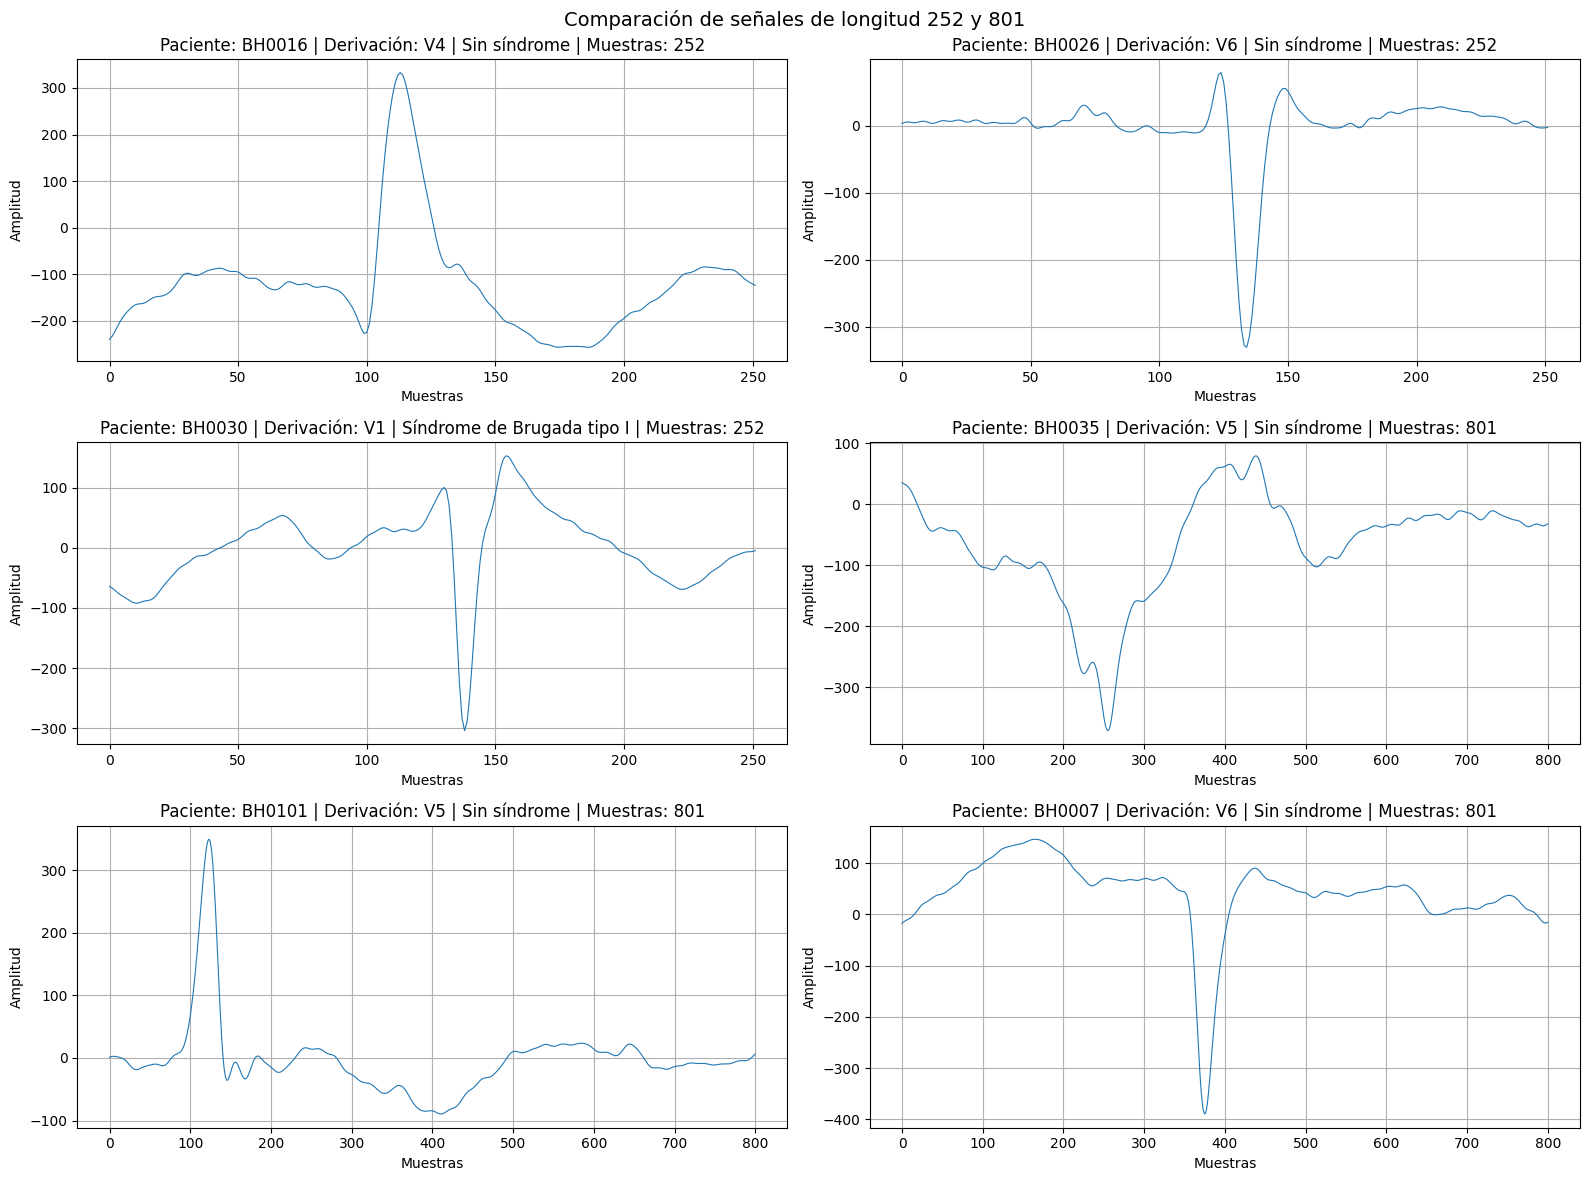

In [15]:
# Select three signals with length 252.
signals_252 = (
    dataset_index[
        dataset_index["signal_length"] == 252
    ]
    .sample(
        n=3,
        random_state=252,
    )
)

# Select three signals with length 801.
signals_801 = (
    dataset_index[
        dataset_index["signal_length"] == 801
    ]
    .sample(
        n=3,
        random_state=801,
    )
)

selected_length_signals = pd.concat(
    [
        signals_252,
        signals_801,
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 12),
)

for axis, (_, row) in zip(
    axes.ravel(),
    selected_length_signals.iterrows(),
):
    ecg_signal = load_signal(row)
    sample_numbers = np.arange(len(ecg_signal))

    axis.plot(
        sample_numbers,
        ecg_signal,
        linewidth=0.8,
    )

    axis.set_title(
        make_signal_title(row)
    )
    axis.set_xlabel("Muestras")
    axis.set_ylabel("Amplitud")
    axis.grid(True)

fig.suptitle(
    "Comparación de señales de longitud 252 y 801",
    fontsize=14,
)

fig.tight_layout()
plt.show()

## 2.8 Final Summary

This notebook has established a structured overview of the ECG recordings and prepared the metadata required for later processing. The main outputs are:

- A complete list of the `.mat` files found in `data/all_signals`.
- A `dataset_index` table with one row per recording and metadata for the patient, lead, class label, original path, and cleaned filename.
- Validation checks for patient identifiers, precordial leads, and the expected class labels `{1, 99}`.
- Patient-level summaries of positive and negative recordings, including a comparison between the `.mat` files and the annotation CSV.
- Signal-level quality information, including the MATLAB variable used, signal length, data type, dimensionality, and the presence of `NaN` or `Inf` values.
- A visual inspection of lead variability, class differences, patient differences, and the two main signal lengths observed in the dataset.

The dataset is now indexed and its main structural characteristics are documented. The next stage can focus on preprocessing decisions, particularly the treatment of different signal lengths, while preserving the patient-level structure required for a reliable train-validation-test split.